# EDA: E-commerce Clickstream Dataset

**Goal:** understand the structure and quality of the 7 raw CSV files before modelling them in Snowflake + dbt (Bronze → Silver → Gold).

**Sections**
1. Load data
2. Schema & shape: table names, table size, column names, data types
3. Data quality: nulls, duplicates, primary keys, foreign keys, formats, business rules
4. Visualizations
5. Findings: how each one is handled in the pipeline
6. Layer plan: Bronze → Silver → Gold


**Data:** [E-commerce Transactions + Clickstream (Kaggle)](https://www.kaggle.com/datasets/wafaaelhusseini/e-commerce-transactions-clickstream)

## 1. Load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

raw_path = Path("../data/raw")
tables = {f.stem: pd.read_csv(f) for f in sorted(raw_path.glob("*.csv"))}
list(tables)

['customers',
 'events',
 'order_items',
 'orders',
 'products',
 'reviews',
 'sessions']

## 2. Schema & shape

In [2]:
overview = pd.DataFrame({n: {"rows": len(df), "columns": df.shape[1]} for n, df in tables.items()}).T
print(f"Total rows: {overview['rows'].sum():,}")
overview

Total rows: 1,005,678


,rows,columns
customers,20000,7
events,760958,10
order_items,59163,5
orders,33580,10
products,1197,6
reviews,10780,6
sessions,120000,6


In [3]:
for name, df in tables.items():
    print(f"\n--- {name} ---")
    print(df.dtypes.to_string())


--- customers ---
customer_id         int64
name                  str
email                 str
country               str
age                 int64
signup_date           str
marketing_opt_in     bool

--- events ---
event_id          int64
session_id        int64
timestamp           str
event_type          str
product_id      float64
qty             float64
cart_size       float64
payment             str
discount_pct    float64
amount_usd      float64

--- order_items ---
order_id            int64
product_id          int64
unit_price_usd    float64
quantity            int64
line_total_usd    float64

--- orders ---
order_id            int64
customer_id         int64
order_time            str
payment_method        str
discount_pct        int64
subtotal_usd      float64
total_usd         float64
country               str
device                str
source                str

--- products ---
product_id      int64
category          str
name              str
price_usd     float64
cost_usd  

In [4]:
# Columns shared by 2+ tables = candidate keys (confirmed by the FK check in section 3)
from collections import defaultdict

col_map = defaultdict(list)
for name, df in tables.items():
    for col in df.columns:
        col_map[col].append(name)

pd.DataFrame([{"column": c, "tables": ", ".join(t)} for c, t in col_map.items() if len(t) > 1])

,column,tables
0,customer_id,"customers, orders, sessions"
1,name,"customers, products"
2,country,"customers, orders, sessions"
3,session_id,"events, sessions"
4,product_id,"events, order_items, products, reviews"
5,discount_pct,"events, orders"
6,order_id,"order_items, orders, reviews"
7,device,"orders, sessions"
8,source,"orders, sessions"


Shared names are only *candidates*. `country`, `device`, `source`, `discount_pct` and `name` are shared **attributes**, not keys. The real relationships are confirmed by the foreign-key check below.

## 3. Data quality

### 3.1 Nulls & duplicate rows

In [16]:
nulls = pd.DataFrame([
    {"table": n, "column": c, "nulls": int(df[c].isna().sum()),
     "null_percentage (%)": round(df[c].isna().mean() * 100, 1)}
    for n, df in tables.items() for c in df.columns if df[c].isna().any()
])
dups = pd.Series({n: int(df.duplicated().sum()) for n, df in tables.items()}, name="duplicate_rows")

display(nulls)
display(dups.to_frame())

,table,column,nulls,null_percentage (%)
0,events,product_id,78489,10.3
1,events,qty,617832,81.2
2,events,cart_size,716049,94.1
3,events,payment,727378,95.6
4,events,discount_pct,727378,95.6
5,events,amount_usd,727378,95.6


,duplicate_rows
customers,0
events,0
order_items,73
orders,0
products,0
reviews,0
sessions,0


In [18]:
# events: nulls depend on event type (e.g. payment only exists on purchases)
events = tables["events"]
events.drop(columns=["event_id", "session_id", "timestamp", "event_type"]).notna().groupby(events.event_type).sum()

,product_id,qty,cart_size,payment,discount_pct,amount_usd
event_type,,,,,,
add_to_cart,143126,143126,0,0,0,0
checkout,0,0,44909,0,0,0
page_view,539343,0,0,0,0,0
purchase,0,0,0,33580,33580,33580


**Note:** Each event type only fills in the fields that make sense for it:

- **page_view:** which product was viewed (`product_id`)
- **add_to_cart:** which product, and how many (`product_id`, `qty`)
- **checkout:** how many items are in the cart (`cart_size`)
- **purchase:** payment details (`payment`, `discount_pct`, `amount_usd`)

So the nulls are **by design, not missing data**. 

Silver tests check these fields only for the matching `event_type`.

### 3.2 Primary-key uniqueness

In [10]:
primary_keys = {"customers": ["customer_id"], "products": ["product_id"], "sessions": ["session_id"],
                "events": ["event_id"], "orders": ["order_id"],
                "order_items": ["order_id", "product_id"], "reviews": ["review_id"]}

pd.DataFrame({t: {"primary_key": ", ".join(c), "duplicate_keys": int(tables[t].duplicated(c).sum())}
              for t, c in primary_keys.items()}).T

,primary_key,duplicate_keys
customers,customer_id,0
products,product_id,0
sessions,session_id,0
events,event_id,0
orders,order_id,0
order_items,"order_id, product_id",110
reviews,review_id,0


**Note:** A primary key is the column that identifies each row, and it should be unique.

- **6 of 7 tables:** each ID appears only once ✅
- **order_items:** has no single ID column, so a row is identified by **order + product** together. In **110 rows**, the same product appears more than once in the same order.

This is **not an error**: a customer can add the same product to an order more than once (see 3.5).

Later, in Silver, these rows are combined into one row per order and product, with a single **surrogate key** `order_item_key`: a hash of `order_id + product_id` (see [why surrogate keys](https://docs.getdbt.com/blog/sql-surrogate-keys)). The implementation depends on the tech stack:

- **Snowflake + dbt:** [`dbt_utils.generate_surrogate_key`](https://github.com/dbt-labs/dbt-utils#generate_surrogate_key-source)
- **Databricks + PySpark:** [`F.md5`](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.functions.md5.html) over `concat_ws("-", ...)`, the same recipe, so both produce identical keys

### 3.3 Foreign-key orphans (child rows with no parent)

In [11]:
foreign_keys = [("sessions", "customer_id", "customers"), ("orders", "customer_id", "customers"),
                ("events", "session_id", "sessions"), ("events", "product_id", "products"),
                ("order_items", "order_id", "orders"), ("order_items", "product_id", "products"),
                ("reviews", "order_id", "orders"), ("reviews", "product_id", "products")]

pd.DataFrame([{"child": f"{c}.{col}", "parent": p,
               "orphans": int((~tables[c][col].dropna().isin(tables[p][col])).sum())}
              for c, col, p in foreign_keys])

,child,parent,orphans
0,sessions.customer_id,customers,0
1,orders.customer_id,customers,0
2,events.session_id,sessions,0
3,events.product_id,products,0
4,order_items.order_id,orders,0
5,order_items.product_id,products,0
6,reviews.order_id,orders,0
7,reviews.product_id,products,0


### 3.4 Formats

In [12]:
print("signup_date:      ", tables["customers"].signup_date.head(3).tolist())        # M/D/YYYY, unlike other dates
print("order_time:       ", tables["orders"].order_time.head(2).tolist())            # ISO 8601
print("events.product_id:", tables["events"].product_id.dropna().head(3).tolist())   # float, should be int
print("countries:        ", sorted(tables["customers"].country.unique()))
print("event types:      ", tables["events"].event_type.unique().tolist())

signup_date:       ['9/4/2020', '4/5/2020', '8/31/2023']
order_time:        ['2025-01-31T23:07:42', '2024-02-19T01:17:50']
events.product_id: [93.0, 1005.0, 1005.0]
countries:         ['AE', 'AU', 'BR', 'CA', 'DE', 'ES', 'FR', 'GB', 'IN', 'JP', 'MX', 'NL', 'PL', 'SE', 'SG', 'US', 'ZA']
event types:       ['page_view', 'add_to_cart', 'checkout', 'purchase']


### 3.5 Business rules

In [13]:
orders, items, reviews = tables["orders"], tables["order_items"], tables["reviews"]
sessions = tables["sessions"]

# 1. total = subtotal × (1 − discount)
r1 = int(((orders.subtotal_usd * (1 - orders.discount_pct / 100)).round(2) - orders.total_usd).abs().gt(0.02).sum())

# 2. subtotal = sum of line items: with vs without the 73 duplicate rows
def subtotal_mismatches(df):
    s = df.groupby("order_id").line_total_usd.sum().reindex(orders.order_id).fillna(0)
    return int((s.values - orders.subtotal_usd.values).__abs__().__gt__(0.02).sum())

r2_keep, r2_dedup = subtotal_mismatches(items), subtotal_mismatches(items.drop_duplicates())

# 3. reviews dated before their order
rv = reviews.merge(orders[["order_id", "order_time"]], on="order_id")
r3 = int((pd.to_datetime(rv.review_time) < pd.to_datetime(rv.order_time)).sum())

# 4. purchase events → orders (no order_id in events: join on customer_id + timestamp)
purchases = events[events.event_type == "purchase"].merge(sessions[["session_id", "customer_id"]], on="session_id")
r4 = len(purchases.merge(orders, left_on=["customer_id", "timestamp"], right_on=["customer_id", "order_time"]))

print(f"total ≠ subtotal × (1 - discount):     {r1}")
print(f"subtotal mismatches, keep dup lines:   {r2_keep}")
print(f"subtotal mismatches, drop dup lines:   {r2_dedup}")
print(f"reviews dated before their order:      {r3:,}")
print(f"purchase events matched to orders:     {r4:,} / {len(purchases):,}")

total ≠ subtotal × (1 - discount):     0
subtotal mismatches, keep dup lines:   0
subtotal mismatches, drop dup lines:   73
reviews dated before their order:      5,482
purchase events matched to orders:     33,580 / 33,580


**Key result:** The 73 duplicate `order_items` rows are valid repeated purchases. Removing them breaks 73 order subtotals, so they are **kept**.

## 4. Visualizations

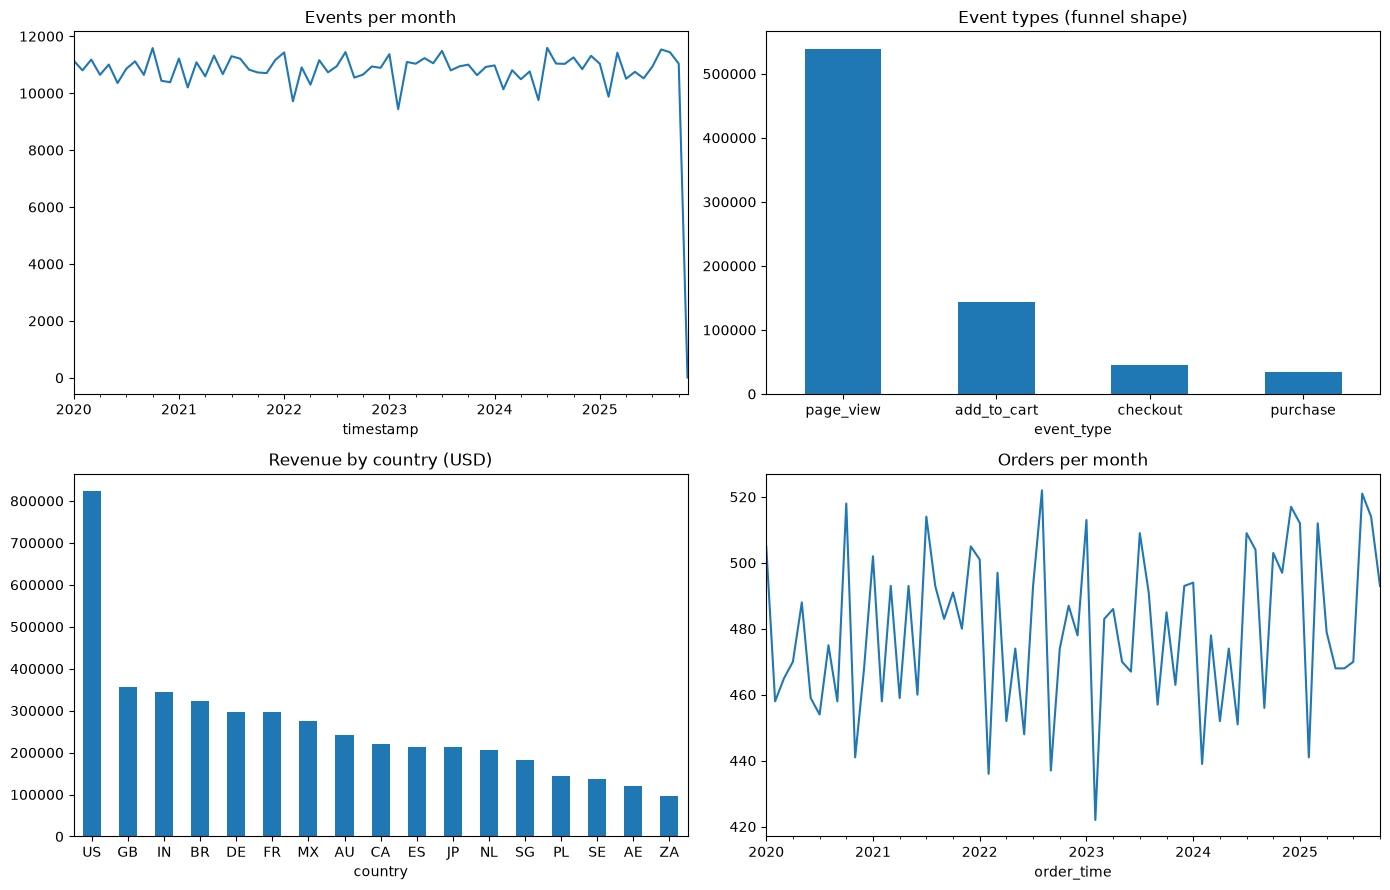

In [14]:
ev = events.assign(timestamp=pd.to_datetime(events.timestamp))
od = orders.assign(order_time=pd.to_datetime(orders.order_time))
funnel = events.event_type.value_counts().reindex(["page_view", "add_to_cart", "checkout", "purchase"])

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
ev.set_index("timestamp").resample("ME").size().plot(ax=ax[0, 0], title="Events per month")
funnel.plot.bar(ax=ax[0, 1], title="Event types (funnel shape)", rot=0)
orders.groupby("country").total_usd.sum().sort_values(ascending=False).plot.bar(
    ax=ax[1, 0], title="Revenue by country (USD)", rot=0)
od.set_index("order_time").resample("ME").size().plot(ax=ax[1, 1], title="Orders per month")
plt.tight_layout()

Path("../docs/images").mkdir(parents=True, exist_ok=True)
plt.savefig("../docs/images/eda_overview.png", dpi=300)
plt.show()

**Notes:** volumes are stable from 2020 to 2025. Sessions and orders end on 2025-10-31; the drop in the last point of *Events per month* comes from a few events spilling into 2025-11-01, not from a data gap.

## 5. Findings

Each finding below drives a design decision in the pipeline:

| # | Finding | Handling in the pipeline |
|---|---|---|
| 1 | 7 tables, 1,005,678 rows, consistent key names | `source()` for every table |
| 2 | 0 FK orphans across 8 relationships | `relationships` tests |
| 3 | `events` nulls only on fields that depend on event type | Expected; conditional tests |
| 4 | `order_items`: 110 rows share an `(order_id, product_id)` key (73 exact repeats); all are needed for subtotals to reconcile | **Keep** them; aggregate to the `(order_id, product_id)` grain + surrogate key `order_item_key` |
| 5 | `events.product_id` stored as float | Cast to integer in Bronze |
| 6 | `customers.signup_date` is `M/D/YYYY` | Parse as date (`M/D/YYYY`) in Bronze |
| 7 | 5,482 reviews dated before their order | Flag column + custom test (`severity: warn`) |
| 8 | Purchase events link to orders via `customer_id + timestamp` (100% match) | Join logic in `fct_orders` |
| 9 | Clean ISO-2 country codes; US leads with ~18% of revenue | `relationships` test against the `country_codes` seed (all 249 ISO 3166-1 countries) |
| 10 | Funnel shape confirmed (views > cart > checkout > purchase) | Supports `mart_conversion_funnel` |
| 11 | Sessions span 2020-01 to 2025-10 (complete); a few events spill into 2025-11-01 | Time-based marts drop the last month only if it is incomplete |
| 12 | `customers` contains PII (`name`, `email`) | Kept in RAW only; Silver exposes a SHA-256 `email_hash`; Gold has no personal data |

## 6. Layer plan


Medallion architecture: each layer has one job:

- **Bronze:** standardize raw data (names + types), no business logic
- **Silver:** clean, join and test, one row per entity or event
- **Gold:** aggregate into business-ready metrics for reporting and decision making


### 6.1. Bronze: `src_*` (ephemeral): rename + cast only, no business logic

| Model | Source table | Changes | Finding |
|---|---|---|---|
| `src_customers` | `customers` | `signup_date` → DATE (parsed from `M/D/YYYY`); `name` → `customer_name`; `marketing_opt_in` → `is_marketing_opt_in` | #6 |
| `src_products` | `products` | `name` → `product_name`; prices → `NUMBER(10,2)` | |
| `src_sessions` | `sessions` | `start_time` → `session_started_at` (TIMESTAMP); `source` → `traffic_source` | |
| `src_events` | `events` | `timestamp` → `event_at` (TIMESTAMP); `product_id`, `qty` → `quantity`, `cart_size` → INTEGER; `payment` → `payment_method` | #5 |
| `src_orders` | `orders` | `order_time` → `ordered_at` (TIMESTAMP); `source` → `traffic_source` | |
| `src_order_items` | `order_items` | Types only, **no dedup** | #4 |
| `src_reviews` | `reviews` | `review_time` → `reviewed_at` (TIMESTAMP) | |

### 6.2. Silver: `dim_*` / `fct_*` (table): clean, join, one row per grain

| Model | Grain (one row per) | Logic | Tests | Finding |
|---|---|---|---|---|
| `dim_customers` | customer | From `src_customers` + `country_name` (seed); `email_hash` (SHA-256); name/email dropped | `unique` + `not_null` (`customer_id`, `email_hash`); `relationships` → `country_codes` | #9, #12 |
| `dim_products` | product | From `src_products` | `unique`, `not_null` | |
| `fct_sessions` | session | Session attributes + event counts + `has_purchase` flag | `unique`, `relationships` → `dim_customers` | #2 |
| `fct_events` | event | From `src_events` | `unique`, `relationships` → `fct_sessions`, `dim_products`; `accepted_values` (event_type) | #2, #3 |
| `fct_orders` | order | Orders + `session_id` via `customer_id + timestamp` | `unique`, `relationships` → `dim_customers`; custom: total = subtotal × (1 − discount) | #8 |
| `fct_order_items` | `(order_id, product_id)` | `GROUP BY` the grain: `SUM(quantity)`, `SUM(line_total_usd)`; add `order_item_key` (hash) | `unique` + `not_null` on `order_item_key`; custom: Σ line totals = order subtotal | #4 |
| `fct_reviews` | review | Reviews + `is_review_before_order` flag | `unique`, `accepted_values` (rating 1-5); custom: review before order (`warn`) | #7 |

### 6.3. Gold: `mart_*` (table): business-ready answers

| Model | Grain | Key metrics | Business question |
|---|---|---|---|
| `mart_session_metrics` | month × device × source × country | Sessions, conversion rate, revenue, revenue per session, avg order value | Which channels and devices convert best? |
| `mart_conversion_funnel` | month × device | Sessions reaching view → cart → checkout → purchase; conversion rate per step | Where do users drop out? |
| `mart_product_performance` | product | Units sold, revenue, gross profit, views, add-to-carts, average rating | Which products and categories drive profit? |

Time-based marts drop the last month only if it is incomplete (#11).